In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [2]:
observations = 1000

xs = np.random.uniform(-10, 10, size=(observations, 1))
zs = np.random.uniform(-10, 10, size=(observations, 1))

generated_inputs = np.column_stack((xs, zs))
noise = np.random.uniform(-1, 1, size=(observations, 1))
generated_targets = 2 * xs - 3 * zs + 5 + noise

np.savez('tf_intro', inputs=generated_inputs, targets=generated_targets)

In [3]:
data = np.load('tf_intro.npz')

In [16]:
input_size = 2
output_size = 1

model = tf.keras.Sequential([tf.keras.layers.Dense(
    output_size,
    kernel_initializer=tf.random_uniform_initializer(-0.1, 0.1),
    bias_initializer=tf.random_uniform_initializer(-0.1, 0.1)
)])
custom_optimizer = tf.keras.optimizers.SGD(learning_rate=0.02)
model.compile(optimizer=custom_optimizer, loss='mean_squared_error')
model.fit(data['inputs'], data['targets'], epochs=100, verbose=2)

Epoch 1/100
32/32 - 0s - 3ms/step - loss: 36.6623
Epoch 2/100
32/32 - 0s - 452us/step - loss: 1.3402
Epoch 3/100
32/32 - 0s - 439us/step - loss: 0.4756
Epoch 4/100
32/32 - 0s - 419us/step - loss: 0.4038
Epoch 5/100
32/32 - 0s - 421us/step - loss: 0.3960
Epoch 6/100
32/32 - 0s - 415us/step - loss: 0.3948
Epoch 7/100
32/32 - 0s - 415us/step - loss: 0.3945
Epoch 8/100
32/32 - 0s - 417us/step - loss: 0.3944
Epoch 9/100
32/32 - 0s - 421us/step - loss: 0.3944
Epoch 10/100
32/32 - 0s - 425us/step - loss: 0.3944
Epoch 11/100
32/32 - 0s - 418us/step - loss: 0.3944
Epoch 12/100
32/32 - 0s - 415us/step - loss: 0.3944
Epoch 13/100
32/32 - 0s - 421us/step - loss: 0.3944
Epoch 14/100
32/32 - 0s - 412us/step - loss: 0.3944
Epoch 15/100
32/32 - 0s - 422us/step - loss: 0.3944
Epoch 16/100
32/32 - 0s - 417us/step - loss: 0.3944
Epoch 17/100
32/32 - 0s - 420us/step - loss: 0.3944
Epoch 18/100
32/32 - 0s - 423us/step - loss: 0.3944
Epoch 19/100
32/32 - 0s - 418us/step - loss: 0.3944
Epoch 20/100
32/32 - 0

In [17]:
model.layers[0].get_weights()

[array([[ 2.0581977],
        [-3.0501008]], dtype=float32),
 array([5.0291986], dtype=float32)]

In [18]:
weights = model.layers[0].get_weights()[0]
bias = model.layers[0].get_weights()[1]

print(weights, bias)

[[ 2.0581977]
 [-3.0501008]] [5.0291986]


In [19]:
model.predict_on_batch(data['inputs']).round(1)

array([[  3.6],
       [ 20.4],
       [-38.3],
       [ 36.6],
       [ -5.4],
       [-27.4],
       [ 12. ],
       [ 33.2],
       [ 39.2],
       [ 46. ],
       [  5. ],
       [ 28. ],
       [-11.1],
       [-17.8],
       [ 23.6],
       [ 11.2],
       [-12.6],
       [ 49.1],
       [ 41.5],
       [  7.1],
       [ 36.4],
       [  7.9],
       [-11.4],
       [ 18.8],
       [  1.2],
       [ 20.7],
       [  4.2],
       [ -9.7],
       [ 29.3],
       [-17.3],
       [-29.7],
       [ 14. ],
       [ 29.6],
       [  6.9],
       [ 23.3],
       [ 16.2],
       [-11.2],
       [  7. ],
       [  7.5],
       [-19.7],
       [  8. ],
       [ 23.3],
       [ 13.6],
       [  0.1],
       [ -9. ],
       [ 10.8],
       [ -9.3],
       [ 40.1],
       [ 51. ],
       [-25. ],
       [ 16.3],
       [  0.2],
       [  0.8],
       [ 14.2],
       [ 35.1],
       [-13.8],
       [ 15.6],
       [ -2.5],
       [ -5.3],
       [ 21. ],
       [ -1.4],
       [ -8.3],
       [

In [20]:
data['targets'].round(1)

array([[  2.8],
       [ 19.6],
       [-37.7],
       [ 36.6],
       [ -5. ],
       [-27.3],
       [ 11.6],
       [ 32.7],
       [ 37.7],
       [ 45.8],
       [  5.6],
       [ 28. ],
       [-10.2],
       [-17.4],
       [ 22.7],
       [ 10.3],
       [-11.3],
       [ 48.6],
       [ 40.9],
       [  8.1],
       [ 35.6],
       [  8.5],
       [-11.2],
       [ 19.3],
       [  1.8],
       [ 21. ],
       [  5.1],
       [ -9.9],
       [ 28.3],
       [-16.3],
       [-28.2],
       [ 13.2],
       [ 29.5],
       [  7.8],
       [ 23.6],
       [ 15.6],
       [-10.2],
       [  7.1],
       [  8.1],
       [-20.1],
       [  8.8],
       [ 22.1],
       [ 14.5],
       [ -0.6],
       [ -8.9],
       [ 11. ],
       [-10. ],
       [ 40.2],
       [ 49.2],
       [-24.9],
       [ 16.3],
       [  0.1],
       [  1.9],
       [ 15.1],
       [ 35.4],
       [-14.2],
       [ 14.6],
       [ -2.7],
       [ -6. ],
       [ 20.6],
       [ -0.7],
       [ -8.6],
       [

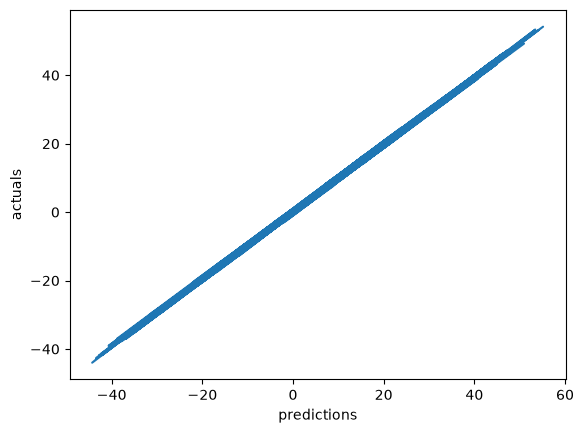

In [21]:
plt.plot(np.squeeze(model.predict_on_batch(data['inputs'])), np.squeeze(data['targets']))
plt.xlabel('predictions')
plt.ylabel('actuals')
plt.show()